<a href="https://colab.research.google.com/github/Ziad-Gebril/Linear-Models-and-Support-Vector-Machines/blob/develop/ML_assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPORTS**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split



# **Part A**

In [2]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits,load_iris

diabetes = load_diabetes(scaled = False)
XD = diabetes.data
YD = diabetes.target

cancer = load_breast_cancer()
XC = cancer.data
YC = 1 - cancer.target    # flipping the data

digits = load_digits()
XDG = digits.data / 16  # dividing the digits data by 16
YDG = digits.target

iris = load_iris()
XI = iris.data
YI = iris.target

In [3]:
XD_tr, XD_te, yD_tr, yD_te = train_test_split(XD, YD, test_size=0.2, random_state=42)
XD_tr, XD_va, yD_tr, yD_va = train_test_split(XD_tr, yD_tr, test_size=0.25, random_state=42)

XC_tr, XC_te, yC_tr, yC_te = train_test_split(XC, YC, test_size=0.2, random_state=42, stratify=YC)
XC_tr, XC_va, yC_tr, yC_va = train_test_split(XC_tr, yC_tr, test_size=0.25, random_state=42, stratify=yC_tr)

XDG_tr, XDG_te, yDG_tr, yDG_te = train_test_split(XDG, YDG, test_size=0.2, random_state=42, stratify=YDG)
XDG_tr, XDG_va, yDG_tr, yDG_va = train_test_split(XDG_tr, yDG_tr, test_size=0.25, random_state=42, stratify=yDG_tr)

XI_tr, XI_te, yI_tr, yI_te = train_test_split(XI, YI, test_size=0.2, random_state=42, stratify=YI)
XI_tr, XI_va, yI_tr, yI_va = train_test_split(XI_tr, yI_tr, test_size=0.25, random_state=42, stratify=yI_tr)

In [4]:
for name, y_tr, y_va, y_te in [
    ("Cancer", yC_tr, yC_va, yC_te),
    ("Digits", yDG_tr, yDG_va, yDG_te),
    ("Iris", yI_tr, yI_va, yI_te)
]:
    print(f"\n{name}")
    print("Train:", np.unique(y_tr, return_counts=True))
    print("Validation:", np.unique(y_va, return_counts=True))
    print("Test:", np.unique(y_te, return_counts=True))


Cancer
Train: (array([0, 1]), array([214, 127]))
Validation: (array([0, 1]), array([71, 43]))
Test: (array([0, 1]), array([72, 42]))

Digits
Train: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Test: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

Iris
Train: (array([0, 1, 2]), array([30, 30, 30]))
Validation: (array([0, 1, 2]), array([10, 10, 10]))
Test: (array([0, 1, 2]), array([10, 10, 10]))


In [5]:
print("Diabetes:", len(yD_tr), len(yD_va), len(yD_te))
print("Cancer:", len(yC_tr), len(yC_va), len(yC_te))
print("Digits:", len(yDG_tr), len(yDG_va), len(yDG_te))
print("Iris:", len(yI_tr), len(yI_va), len(yI_te))

Diabetes: 264 89 89
Cancer: 341 114 114
Digits: 1077 360 360
Iris: 90 30 30


In [6]:
class S:
    pass

def Standardizer_fit(SS,X):
  SS.mean = np.mean(X,axis = 0)
  SS.std = np.std(X,axis = 0)


  n=len(SS.std)
  i=0
  while(i<n):
    if (SS.std[i]==0):
      SS.std[i] = 1
    i+=1

  return SS


def transform(SS, X):
      return (X - SS.mean) / SS.std   # z= (x-m)/o'


def add_bias(XX):
  one = np.ones((len(XX),1))
  X = np.column_stack((one,XX))
  return X

In [7]:
# made the test with Ai
# Diabetes
scaler_D = S()
Standardizer_fit(scaler_D, XD_tr)

XD_tr = transform(scaler_D, XD_tr)
XD_va = transform(scaler_D, XD_va)
XD_te = transform(scaler_D, XD_te)


# Cancer
scaler_C = S()
Standardizer_fit(scaler_C, XC_tr)

XC_tr = transform(scaler_C, XC_tr)
XC_va = transform(scaler_C, XC_va)
XC_te = transform(scaler_C, XC_te)


# Iris
scaler_I = S()
Standardizer_fit(scaler_I, XI_tr)

XI_tr = transform(scaler_I, XI_tr)
XI_va = transform(scaler_I, XI_va)
XI_te = transform(scaler_I, XI_te)


for name, X_tr, X_va, X_te in [
    ("Diabetes", XD_tr, XD_va, XD_te),
    ("Cancer", XC_tr, XC_va, XC_te),
    ("Iris", XI_tr, XI_va, XI_te)
]:
    print(f"\n{name}")
    print("Train mean:", np.round(X_tr.mean(axis=0), 6))
    print("Train std:", np.round(X_tr.std(axis=0), 6))


Diabetes
Train mean: [-0.  0. -0. -0. -0. -0.  0. -0.  0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Cancer
Train mean: [ 0.  0. -0.  0. -0. -0.  0. -0.  0. -0.  0.  0. -0. -0. -0.  0. -0. -0.
  0. -0. -0.  0. -0. -0. -0.  0.  0. -0.  0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Iris
Train mean: [-0.  0. -0.  0.]
Train std: [1. 1. 1. 1.]


In [8]:
def mse(y_t, y_p):
  errors = y_t - y_p
  return np.mean(np.array(errors) ** 2)


def rmse(y_t, y_p):
  return np.sqrt(mse(y_t, y_p))


def r2(y_t, y_p):
  s1= np.sum((y_t-y_p)**2) # comparing each one to the predicted one
  s2 = np.sum(( np.mean(y_t)-y_t)**2) # comparing each one to the mean of all of them
  return 1-(s1/s2)


def accuracy(y_t, pred):
  T= np.sum(y_t == pred)
  total = len(y_t)
  return T/total

#def conf_matrix(y, pred):
 # classesT =np.unique(y)
  #CM = np.zeros((K,K))
##
 # classesP =np.unique(y)
 #
  #i=0
#
 # while(i<K):
  #  TR = np.where(classesT == y[i])[0][0]
   # PR = np.where(classesP == pred[i])[0][0]
    #CM[TR][PR] += 1
#
 #   i+=1
#
 # return CM\\

def confusion_matrix(y, pred, K):
    CM = np.bincount(
        K * y + pred,
        minlength=K * K
    ).reshape(K, K)

    return CM

In [9]:
def precision(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  PR = np.zeros(n)

  while(i<n):
    if np.sum(CM[:, i]) == 0:
      PR[i] = 0
      # Precision = 0 for a class that is never predicted
    else:
      PR[i] = d[i]/np.sum(CM[:, i]) # to take only one column
    i+=1
  return PR

def recall(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  RC = np.zeros(n)

  while(i<n):
    if np.sum(CM[i, :]) == 0:
      RC[i] = 0
      # recall = 0 for a class that is never Existed
    else:
      RC[i] = d[i]/np.sum(CM[i, :]) # to take only one row
    i+=1
  return RC


def F1(CM):
  P = precision(CM)
  R = recall(CM)

  n=len(P)
  i=0
  F = np.zeros(n)

  while(i<n):
    NOM = P[i]*R[i]
    DNOM = P[i]+R[i]
    if DNOM == 0:
      F[i] = 0
    else:
      F[i]= 2*NOM/DNOM
    i+=1
  return F

In [10]:
y_t = np.array([0, 1, 2, 0, 1])
y_p = np.array([0, 1, 0, 2, 1])

classes =np.unique(y_t)
n = len(classes)

CM = confusion_matrix(y_t, y_p, n)

macro_precision = np.mean(precision(CM))
macro_recall = np.mean(recall(CM))
macro_F1 = np.mean(F1(CM))


print("Precision:", precision(CM))
print("Macro Precision:", macro_precision)

print("Recall:", recall(CM))
print("Macro Recall:", macro_recall)

print("F1:", F1(CM))
print("Macro F1:", macro_F1)

Precision: [0.5 1.  0. ]
Macro Precision: 0.5
Recall: [0.5 1.  0. ]
Macro Recall: 0.5
F1: [0.5 1.  0. ]
Macro F1: 0.5


In [11]:
print(CM)
print(precision(CM))
print(F1(CM))

[[1 0 1]
 [0 2 0]
 [1 0 0]]
[0.5 1.  0. ]
[0.5 1.  0. ]


In [12]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support
)

rng = np.random.default_rng(42)

N = 500
K = 4

# Regression
y_reg = rng.normal(size=N)
pred_reg = rng.normal(size=N)

# Classification
y = rng.integers(0, K, size=N)
pred = rng.integers(0, K, size=N)

In [13]:
np.testing.assert_allclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

print("Regression metrics: PASSED")

Regression metrics: PASSED


In [14]:
CM = confusion_matrix(y, pred, K)

CM_ref = sk_confusion_matrix(
    y, pred,
    labels=np.arange(K)
)

np.testing.assert_array_equal(CM, CM_ref)

print("Confusion matrix: PASSED")

Confusion matrix: PASSED


In [15]:
P_ref, R_ref, F_ref, _ = precision_recall_fscore_support(
    y, pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)

np.testing.assert_allclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    precision(CM), P_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    recall(CM), R_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    F1(CM), F_ref,
    atol=1e-12, rtol=0
)

print("Classification metrics: PASSED")

Classification metrics: PASSED


In [16]:
np.testing.assert_allclose(
    np.mean(precision(CM)),
    np.mean(P_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(recall(CM)),
    np.mean(R_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(F1(CM)),
    np.mean(F_ref),
    atol=1e-12, rtol=0
)

print("Macro averages: PASSED")

Macro averages: PASSED


In [17]:
def grad_check(f, grad, w, eps=1e-5):
    w = np.array(w, dtype=float)

    g_analytic = grad(w).flatten()
    g_numeric = np.zeros(w.size)

    # Select entries to check
    rng = np.random.default_rng(42)

    if w.size > 100:
        indices = rng.choice(w.size, size=100, replace=False)
    else:
        indices = np.arange(w.size)

    # Central differences
    for i in indices:
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        g_numeric[i] = (f(w_plus) - f(w_minus)) / (2 * eps)

    # Compare only the selected entries
    g_a = g_analytic[indices]
    g_n = g_numeric[indices]

    numerator = np.linalg.norm(g_a - g_n)
    denominator = max(
        np.linalg.norm(g_a),
        np.linalg.norm(g_n),
        1e-12
    )

    return numerator / denominator

In [18]:
# a test fro grad from the AI

def test_f(w):
    return np.sum(w**2)

def test_grad(w):
    return 2*w

rng = np.random.default_rng(42)
w = rng.normal(0, 0.1, size=5)

error = grad_check(test_f, test_grad, w)

print("Relative error:", error)
print("Passed:", error < 1e-6)

Relative error: 1.1752888136783617e-12
Passed: True


# **Part D**

Binary soft-margin linear SVM: $f(x) = w\cdot x + b$, $y \in \{-1,+1\}$,

$$J(w,b) = \frac{\lambda}{2}\|w\|^2 + \frac{1}{N}\sum_i \max(0,\, 1 - y_i f(x_i))$$

Subgradient (the bias $b$ is not regularized), with $\mathcal{A} = \{i : y_i f(x_i) < 1\}$:

$$\partial_w J = \lambda w - \frac{1}{N}\sum_{i\in\mathcal{A}} y_i x_i, \qquad \partial_b J = -\frac{1}{N}\sum_{i\in\mathcal{A}} y_i$$

## **Task 23: Linear SVM from scratch (Breast Cancer)**

In [19]:
from sklearn.svm import SVC, LinearSVC

# labels in {-1, +1}
yC_tr_pm = 2 * yC_tr - 1
yC_va_pm = 2 * yC_va - 1
yC_te_pm = 2 * yC_te - 1

lam = 0.01


def svm_objective(w, b, X, y, lam):
  margins = y * (X @ w + b)
  return lam / 2 * (w @ w) + np.mean(np.maximum(0, 1 - margins))


def svm_subgrad(w, b, X, y, lam):
  N = len(y)
  margins = y * (X @ w + b)
  active = margins < 1          # points that violate the margin
  gw = lam * w - (X[active].T @ y[active]) / N
  gb = -np.sum(y[active]) / N
  return gw, gb


def svm_predict(w, b, X):
  return np.where(X @ w + b >= 0, 1, -1)

In [20]:
# grad_check works on a single vector, so pack theta = [b, w]
f_svm = lambda th: svm_objective(th[1:], th[0], XC_tr, yC_tr_pm, lam)

def g_svm(th):
  gw, gb = svm_subgrad(th[1:], th[0], XC_tr, yC_tr_pm, lam)
  return np.concatenate(([gb], gw))

rng = np.random.default_rng(42)
theta0 = rng.normal(0, 0.1, size=XC_tr.shape[1] + 1)

err = grad_check(f_svm, g_svm, theta0, eps=1e-6)
print("Relative error:", err)
print("Passed:", err < 1e-5)

Relative error: 8.834486966968906e-11
Passed: True


In [21]:
def train_svm(X, y, lam, iters, step, X_va=None, y_va=None):
  # full-batch subgradient descent, step(t) gives eta_t for t = 1, 2, ...
  w = np.zeros(X.shape[1])
  b = 0.0
  best = (np.inf, w.copy(), b)
  obj_hist, va_hist = [], []

  for t in range(1, iters + 1):
    gw, gb = svm_subgrad(w, b, X, y, lam)
    eta = step(t)
    w = w - eta * gw
    b = b - eta * gb

    J = svm_objective(w, b, X, y, lam)
    obj_hist.append(J)
    if J < best[0]:
      best = (J, w.copy(), b)
    if X_va is not None:
      va_hist.append(accuracy(y_va, svm_predict(w, b, X_va)))

  return w, b, np.array(obj_hist), np.array(va_hist), best


schedules = {
    "constant eta = 0.1": lambda t: 0.1,
    "constant eta = 1.0": lambda t: 1.0,
    "eta_t = 1/sqrt(t)": lambda t: 1.0 / np.sqrt(t),
}

runs = {}
for name, step in schedules.items():
  runs[name] = train_svm(XC_tr, yC_tr_pm, lam, 3000, step, XC_va, yC_va_pm)
  w, b, obj, va, best = runs[name]
  print(f"{name:20s} final J = {obj[-1]:.6f}  best J = {best[0]:.6f}  final val acc = {va[-1]:.4f}")

constant eta = 0.1   final J = 0.060544  best J = 0.060455  final val acc = 0.9737


constant eta = 1.0   final J = 0.060961  best J = 0.060615  final val acc = 0.9737


eta_t = 1/sqrt(t)    final J = 0.060798  best J = 0.060786  final val acc = 0.9737


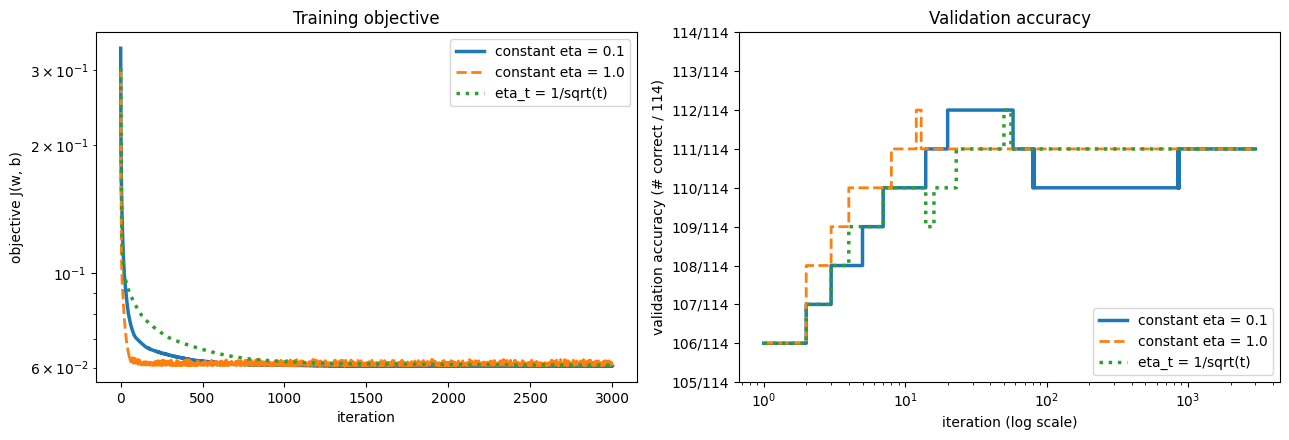

In [22]:
styles = {
    "constant eta = 0.1": dict(ls="-", lw=2.5),
    "constant eta = 1.0": dict(ls="--", lw=2),
    "eta_t = 1/sqrt(t)": dict(ls=":", lw=2.5),
}
iters = np.arange(1, 3001)
n_va = len(yC_va_pm)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (w, b, obj, va, best) in runs.items():
  ax[0].plot(iters, obj, label=name, **styles[name])
  ax[1].step(iters, va, where="post", label=name, **styles[name])

ax[0].set_yscale("log")
ax[0].set_xlabel("iteration")
ax[0].set_ylabel("objective J(w, b)")
ax[0].set_title("Training objective")
ax[0].legend()

# accuracy only moves in steps of 1/n_va and settles within the first few hundred iterations,
# so a log x-axis shows the interesting part
ax[1].set_xscale("log")
ticks = np.arange(105, 115) / n_va
ax[1].set_yticks(ticks, [f"{k}/{n_va}" for k in range(105, 115)])
ax[1].set_xlabel("iteration (log scale)")
ax[1].set_ylabel("validation accuracy (# correct / 114)")
ax[1].set_title("Validation accuracy")
ax[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

The validation set has only 114 points, so validation accuracy moves in steps of $1/114 \approx 0.009$, which is why the curves are staircases. All three schedules end at the same 111/114. With $\eta = 1.0$ it settles by iteration 13 and with $1/\sqrt{t}$ by iteration 56, so the dashed and dotted lines lie on top of each other from there on. With $\eta = 0.1$ one borderline point keeps flipping between correct and wrong until about iteration 866 before it settles too. The objective is the better measure of convergence here: validation accuracy stops changing long before the objective does.

The hinge objective has kinks, and at the optimum some points sit exactly on the margin $y_if(x_i)=1$, so the subgradient does not shrink to zero as we approach the minimum: each step a point flips in or out of the active set and the subgradient jumps by roughly $\|x_i\|/N$. With a constant $\eta$ every step therefore moves the iterate by a non-vanishing amount, so it keeps oscillating around the minimum in a band whose width grows with $\eta$ (clearly visible for $\eta = 1.0$). The schedule $\eta_t = 1/\sqrt{t}$ makes the steps go to zero while their sum still diverges ($\sum \eta_t = \infty$, $\eta_t \to 0$), so the iterate can travel as far as needed but the oscillation dies out and it converges to the minimum. After only 3000 iterations, though, $1/\sqrt{t}$ has shrunk its steps long before reaching the optimum, so it only creeps toward it at the slow $O(1/\sqrt{t})$ rate, while a constant $\eta = 0.1$ gets close fast and its oscillation band is already tiny, so the smaller constant step can still have the lower objective at that point (here 0.06054 vs 0.06080).

## **Task 24: Against scikit-learn**

In [23]:
N_tr = len(yC_tr_pm)
C = 1 / (lam * N_tr)

w_my, b_my, obj_my, _, best_my = train_svm(XC_tr, yC_tr_pm, lam, 20000, lambda t: 1.0 / np.sqrt(t))
# subgradient descent is not a descent method, so keep the best iterate
J_my, w_my, b_my = best_my

svc = SVC(kernel="linear", C=C)
svc.fit(XC_tr, yC_tr_pm)
w_sk = svc.coef_.ravel()
b_sk = svc.intercept_[0]
J_sk = svm_objective(w_sk, b_sk, XC_tr, yC_tr_pm, lam)

rel = abs(J_my - J_sk) / abs(J_sk)
cos = w_my @ w_sk / (np.linalg.norm(w_my) * np.linalg.norm(w_sk))
agree = np.mean(svm_predict(w_my, b_my, XC_te) == svc.predict(XC_te))
n_sv_my = np.sum(yC_tr_pm * (XC_tr @ w_my + b_my) <= 1 + 1e-3)

print(f"C = {C:.5f}")
print(f"objective   mine = {J_my:.6f}   sklearn = {J_sk:.6f}   relative diff = {rel:.2e}   (<= 1e-3: {rel <= 1e-3})")
print(f"cosine similarity of w = {cos:.5f}   (>= 0.99: {cos >= 0.99})")
print(f"test prediction agreement = {agree:.4f}   (>= 0.98: {agree >= 0.98})")
print(f"margin width 2/||w||   mine = {2 / np.linalg.norm(w_my):.4f}   sklearn = {2 / np.linalg.norm(w_sk):.4f}")
print(f"# points with y f(x) <= 1   mine = {n_sv_my}   sklearn n_support_ = {svc.n_support_.sum()}   (within 5: {abs(n_sv_my - svc.n_support_.sum()) <= 5})")

C = 0.29326
objective   mine = 0.060445   sklearn = 0.060437   relative diff = 1.34e-04   (<= 1e-3: True)
cosine similarity of w = 0.99968   (>= 0.99: True)
test prediction agreement = 1.0000   (>= 0.98: True)
margin width 2/||w||   mine = 1.1318   sklearn = 1.1291
# points with y f(x) <= 1   mine = 32   sklearn n_support_ = 32   (within 5: True)


$y_if(x_i) \le 1$ is checked with a tolerance of $10^{-3}$: our solution is only approximate, so points that SVC puts exactly on the margin come out as $1.0001$ or $0.9999$ in ours.

In [24]:
def margin_count(w, b, X, y, tol=1e-3):
  return int(np.sum(y * (X @ w + b) <= 1 + tol))


rows = []
for lam_i in [1e-4, 1e-3, 1e-2, 1e-1, 1]:
  C_i = 1 / (lam_i * N_tr)

  _, _, _, _, (_, w1, b1) = train_svm(XC_tr, yC_tr_pm, lam_i, 20000, lambda t: 1.0 / np.sqrt(t))

  m2 = SVC(kernel="linear", C=C_i).fit(XC_tr, yC_tr_pm)
  w2, b2 = m2.coef_.ravel(), m2.intercept_[0]

  m3 = LinearSVC(loss="hinge", C=C_i, max_iter=200000, random_state=42).fit(XC_tr, yC_tr_pm)
  w3, b3 = m3.coef_.ravel(), m3.intercept_[0]

  for model, w_, b_, nsv in [("mine", w1, b1, margin_count(w1, b1, XC_tr, yC_tr_pm)),
                             ("SVC", w2, b2, m2.n_support_.sum()),
                             ("LinearSVC", w3, b3, margin_count(w3, b3, XC_tr, yC_tr_pm))]:
    rows.append({
        "lambda": lam_i, "C": round(C_i, 5), "model": model,
        "val acc": accuracy(yC_va_pm, svm_predict(w_, b_, XC_va)),
        "margin 2/||w||": 2 / np.linalg.norm(w_),
        "# SV": nsv,
        "objective J": svm_objective(w_, b_, XC_tr, yC_tr_pm, lam_i),
        "b": b_,
    })

sweep = pd.DataFrame(rows)
sweep

,lambda,C,model,val acc,margin 2/||w||,# SV,objective J,b
0,0.0001,29.32551,mine,0.964912,0.592342,21,0.030374,0.275556
1,0.0001,29.32551,SVC,0.947368,0.146007,22,0.009391,1.377309
2,0.0001,29.32551,LinearSVC,0.947368,0.145978,22,0.009386,1.321384
3,0.0010,2.93255,mine,0.973684,0.653870,23,0.035843,0.221193
4,0.0010,2.93255,SVC,0.964912,0.462039,28,0.032165,0.231863
5,0.0010,2.93255,LinearSVC,0.964912,0.463402,28,0.032163,0.202946
6,0.0100,0.29326,mine,0.973684,1.131752,32,0.060445,-0.135978
7,0.0100,0.29326,SVC,0.973684,1.129147,32,0.060437,-0.129009
8,0.0100,0.29326,LinearSVC,0.973684,1.123488,32,0.060444,-0.113523
9,0.1000,0.02933,mine,0.982456,2.168805,61,0.121679,-0.227306


**Where the three disagree and why.**

* **Small λ (1e-4, 1e-3), mine vs. the other two.** Here our objective is clearly higher than SVC's (e.g. 0.030 vs 0.009 at λ = 1e-4) and our margin is much wider, so our solver simply has not converged. With a tiny λ the problem is close to a hard-margin SVM: the optimum needs a large $\|w\|$, the objective is only weakly strongly convex, and subgradient descent with $\eta_t = 1/\sqrt t$ converges at roughly $O(1/\sqrt t)$, so 20,000 iterations are not enough to grow $w$ that far. SVC and LinearSVC solve the dual exactly (SMO / coordinate descent) and agree with each other.
* **Large λ (1e-1, 1), LinearSVC vs. the other two.** Here ours and SVC match to about 6 digits, but LinearSVC has a higher objective, a smaller |b| (-0.13 vs -0.33 at λ = 1) and more points inside the margin. The reason is that liblinear **regularizes the intercept**: it appends a constant feature (`intercept_scaling = 1`) and penalizes its weight like any other, so it minimizes a different objective, $\frac{\lambda}{2}(\|w\|^2 + b^2) + \ldots$. With a large λ the penalty pulls b toward 0, which our $J$ (and SVC's) does not do. With a small λ that extra penalty hardly matters, which is why LinearSVC agrees with SVC there.

## **Task 25: Multiclass hinge vs. softmax (Digits)**

Weston–Watkins loss with $\Delta = 1$, scores $S = \tilde X W$ ($\tilde X$ has the bias column, $W$ is $(d+1)\times K$):

$$L(W) = \frac{1}{N}\sum_i \sum_{j\ne y_i} \max(0,\, S_{ij} - S_{iy_i} + \Delta) + \frac{\lambda}{2}\|W_{1:}\|^2$$

**Gradient.** For one sample, the term $\max(0, S_{ij}-S_{iy_i}+\Delta)$ with $j\neq y_i$ has derivative $+1$ with respect to $S_{ij}$ and $-1$ with respect to $S_{iy_i}$ when it is positive, and $0$ otherwise. So $\partial L_i/\partial S_{ij} = B_{ij}$ with $B_{ij} = \mathbb 1[S_{ij}-S_{iy_i}+\Delta>0]$ for $j\neq y_i$, and $\partial L_i/\partial S_{iy_i} = -\sum_{j\ne y_i} B_{ij} = B_{iy_i}$ (the correct class receives a $-1$ from every violating class). Because $S = \tilde XW$, i.e. $S_{ij} = \tilde x_i^\top W_{:,j}$, the chain rule gives $\partial L/\partial W_{:,j} = \frac1N\sum_i B_{ij}\tilde x_i$, which in matrix form is $\frac1N \tilde X^\top B$. The regularizer only touches the non-bias rows, giving $\lambda[0;\,W_{1:}]$:

$$\frac{\partial L}{\partial W} = \frac1N \tilde X^\top B + \lambda\,[0;\,W_{1:}]$$

In [25]:
XDG_tr_b = add_bias(XDG_tr)
XDG_va_b = add_bias(XDG_va)
XDG_te_b = add_bias(XDG_te)
K_DG = 10


def mc_svm_loss_grad(W, X, y, lam, delta=1.0):
  N = len(y)
  idx = np.arange(N)
  S = X @ W
  M = S - S[idx, y][:, None] + delta     # margins S_ij - S_iy + delta
  M[idx, y] = 0
  loss = np.sum(np.maximum(0, M)) / N + lam / 2 * np.sum(W[1:] ** 2)

  B = (M > 0).astype(float)
  B[idx, y] = -np.sum(B, axis=1)
  reg = np.vstack([np.zeros((1, W.shape[1])), W[1:]])
  grad = X.T @ B / N + lam * reg
  return loss, grad


def softmax_loss_grad(W, X, y, lam):
  N = len(y)
  idx = np.arange(N)
  S = X @ W
  S = S - S.max(axis=1, keepdims=True)  # numerical stability
  P = np.exp(S)
  P = P / P.sum(axis=1, keepdims=True)
  loss = -np.mean(np.log(P[idx, y])) + lam / 2 * np.sum(W[1:] ** 2)

  P[idx, y] -= 1
  reg = np.vstack([np.zeros((1, W.shape[1])), W[1:]])
  grad = X.T @ P / N + lam * reg
  return loss, grad

In [26]:
W0 = np.zeros((XDG_tr_b.shape[1], K_DG))
L0, _ = mc_svm_loss_grad(W0, XDG_tr_b, yDG_tr, lam=0.01)
print("Loss at W = 0:", L0, " expected:", 1.0 * (K_DG - 1), " exact:", L0 == 9.0)

rng = np.random.default_rng(42)
W_rand = rng.normal(0, 0.01, size=W0.shape)
f_mc = lambda W: mc_svm_loss_grad(W, XDG_tr_b, yDG_tr, 0.01)[0]
g_mc = lambda W: mc_svm_loss_grad(W, XDG_tr_b, yDG_tr, 0.01)[1]

err = grad_check(f_mc, g_mc, W_rand)   # checks 100 random entries
print("Relative error:", err)
print("Passed:", err < 1e-5)

Loss at W = 0: 9.0  expected: 9.0  exact: True
Relative error: 4.365388185750168e-10
Passed: True


**Note on the softmax baseline (Task 18).** Task 18 (softmax regression on Digits) is not in this notebook yet. It was done separately as Part D on the `soft_max` branch. So that this task can still compare against softmax, the `softmax_loss_grad` function above is a **stand-in**, trained with exactly the same `train_minibatch` loop and selection protocol as the multiclass SVM (B = 64, 100 epochs, η ∈ {0.01, 0.1, 0.5} by validation loss with λ = 0, then λ ∈ {0, 1e-4, 1e-3, 1e-2} by validation accuracy). Unlike the Weston–Watkins gradient, its gradient was not run through `grad_check` here.

For reference, the Task 18 results on the `soft_max` branch are: selected η = 1.0 (that grid also included 1.0), λ = 1e-3, validation accuracy 0.967, test accuracy 0.953. The stand-in below picks η = 0.5 and λ = 1e-3 and gets 0.967 / 0.958, so the two agree on validation accuracy and differ by 2 test points out of 360. Once the branches are merged, this stand-in should be replaced by the Task 18 code and results.

In [27]:
def train_minibatch(loss_grad, X, y, lam, eta, epochs=100, batch=64, seed=42):
  rng = np.random.default_rng(seed)
  W = np.zeros((X.shape[1], K_DG))
  N = len(y)
  for ep in range(epochs):
    perm = rng.permutation(N)
    for s in range(0, N, batch):
      bi = perm[s:s + batch]
      _, g = loss_grad(W, X[bi], y[bi], lam)
      W = W - eta * g
  return W


def predict_scores(W, X):
  return np.argmax(X @ W, axis=1)


results = {}
for name, lg in [("multiclass SVM", mc_svm_loss_grad), ("softmax", softmax_loss_grad)]:
  # step 1: choose eta by validation loss (lambda = 0)
  eta_loss = {}
  for eta in [0.01, 0.1, 0.5]:
    W = train_minibatch(lg, XDG_tr_b, yDG_tr, 0.0, eta)
    eta_loss[eta] = lg(W, XDG_va_b, yDG_va, 0.0)[0]
  best_eta = min(eta_loss, key=eta_loss.get)

  # step 2: choose lambda by validation accuracy
  lam_acc, lam_W = {}, {}
  for lam_i in [0, 1e-4, 1e-3, 1e-2]:
    W = train_minibatch(lg, XDG_tr_b, yDG_tr, lam_i, best_eta)
    lam_W[lam_i] = W
    lam_acc[lam_i] = accuracy(yDG_va, predict_scores(W, XDG_va_b))
  best_lam = max(lam_acc, key=lam_acc.get)
  W_best = lam_W[best_lam]

  results[name] = {
      "val loss per eta": {k: round(v, 4) for k, v in eta_loss.items()},
      "best eta": best_eta,
      "val acc per lambda": lam_acc,
      "best lambda": best_lam,
      "val acc": lam_acc[best_lam],
      "test acc": accuracy(yDG_te, predict_scores(W_best, XDG_te_b)),
  }

for name, r in results.items():
  print(name)
  for k, v in r.items():
    print(f"  {k}: {v}")

pd.DataFrame({n: {"best eta": r["best eta"], "best lambda": r["best lambda"],
                  "val acc": r["val acc"], "test acc": r["test acc"]} for n, r in results.items()}).T

multiclass SVM
  val loss per eta: {0.01: 0.3126, 0.1: 0.1702, 0.5: 0.1406}
  best eta: 0.5
  val acc per lambda: {0: 0.9611111111111111, 0.0001: 0.9638888888888889, 0.001: 0.9694444444444444, 0.01: 0.9444444444444444}
  best lambda: 0.001
  val acc: 0.9694444444444444
  test acc: 0.95
softmax
  val loss per eta: {0.01: 0.8374, 0.1: 0.239, 0.5: 0.1383}
  best eta: 0.5
  val acc per lambda: {0: 0.9611111111111111, 0.0001: 0.9611111111111111, 0.001: 0.9666666666666667, 0.01: 0.9333333333333333}
  best lambda: 0.001
  val acc: 0.9666666666666667
  test acc: 0.9583333333333334


,best eta,best lambda,val acc,test acc
multiclass SVM,0.5,0.001,0.969444,0.950000
softmax,0.5,0.001,0.966667,0.958333


In [28]:
def mc_svm_single(s, y, delta=1.0):
  s = np.asarray(s, dtype=float)
  m = np.maximum(0, s - s[y] + delta)
  m[y] = 0
  return m.sum()


def softmax_ce_single(s, y):
  s = np.asarray(s, dtype=float)
  s = s - s.max()
  return np.log(np.sum(np.exp(s))) - s[y]


toy = {"(a)": [10, -5, -5], "(b)": [100, -50, -50], "(c)": [3.2, 5.1, -1.7]}
pd.DataFrame({k: {"scores": v, "multiclass SVM loss": mc_svm_single(v, 0),
                  "softmax cross-entropy": softmax_ce_single(v, 0)} for k, v in toy.items()}).T

,scores,multiclass SVM loss,softmax cross-entropy
(a),"[10, -5, -5]",0.0,0.000001
(b),"[100, -50, -50]",0.0,0.0
(c),"[3.2, 5.1, -1.7]",2.9,2.040355


**Toy analysis.** Once the correct class beats every other class by at least $\Delta$, the SVM loss is exactly 0. It stops caring how big that lead is, so (a) and (b) cost the same, and those samples no longer contribute any gradient. Softmax cross-entropy is never exactly 0. It keeps pushing the correct score further above the others ((a) still costs $6\times10^{-7}$, and only the much larger gap in (b) drives it to about 0), so every sample keeps pulling on $W$. In practice the SVM learns scores that only need to clear the margin, and their size means nothing beyond the ranking. That makes them poor probability estimates, and they are not normalized anyway. Softmax scores pass through $\mathrm{softmax}(S)$ to give proper probabilities, but without regularization softmax would keep growing $\|W\|$ to make them overconfident on separable data.

## **Task 26: Kernels and C (Breast Cancer)**

In [29]:
rows = []
for name, model in [
    ("linear", SVC(kernel="linear", C=1)),
    ("poly (deg 3, coef0 1)", SVC(kernel="poly", degree=3, coef0=1, gamma="scale", C=1)),
    ("rbf", SVC(kernel="rbf", gamma="scale", C=1)),
]:
  model.fit(XC_tr, yC_tr)
  rows.append({"kernel": name,
               "train acc": accuracy(yC_tr, model.predict(XC_tr)),
               "val acc": accuracy(yC_va, model.predict(XC_va)),
               "test acc": accuracy(yC_te, model.predict(XC_te)),
               "# SV": model.n_support_.sum()})
pd.DataFrame(rows)

,kernel,train acc,val acc,test acc,# SV
0,linear,0.988270,0.964912,0.929825,30
1,"poly (deg 3, coef0 1)",0.991202,0.982456,0.973684,52
2,rbf,0.982405,0.982456,0.973684,88


In [30]:
rows = []
for C_i in [0.001, 0.01, 0.1, 1, 10, 100]:
  model = SVC(kernel="linear", C=C_i).fit(XC_tr, yC_tr)
  rows.append({"C": C_i,
               "lambda = 1/(C N)": 1 / (C_i * len(yC_tr)),
               "train acc": accuracy(yC_tr, model.predict(XC_tr)),
               "val acc": accuracy(yC_va, model.predict(XC_va)),
               "# SV": model.n_support_.sum(),
               "margin 2/||w||": 2 / np.linalg.norm(model.coef_)})
pd.DataFrame(rows)

,C,lambda = 1/(C N),train acc,val acc,# SV,margin 2/||w||
0,0.001,2.932551,0.932551,0.956140,175,6.761937
1,0.010,0.293255,0.973607,0.973684,83,3.168999
2,0.100,0.029326,0.979472,0.964912,43,1.566853
3,1.000,0.002933,0.988270,0.964912,30,0.672679
4,10.000,0.000293,0.997067,0.938596,23,0.247084
5,100.000,0.000029,1.000000,0.947368,22,0.146007


**C and λ.** SVC minimizes $\frac12\|w\|^2 + C\sum_i \xi_i$. Dividing by $CN$ gives $\frac{1}{2CN}\|w\|^2 + \frac1N\sum_i\xi_i$, which is our $J$ with $\lambda = 1/(CN)$, so a large C means a tiny λ. A large C asks the SVM to classify almost every training point correctly and outside the margin, even if that takes a large $\|w\|$ (a narrow margin). Margin violations become expensive, so few points stay inside the margin, the support vectors drop, and training accuracy climbs toward 1. The price is that the boundary starts fitting individual points, i.e. it overfits.

## **Task 27: Effect of γ (RBF, two features)**

In [31]:
feat = [list(cancer.feature_names).index("mean radius"), list(cancer.feature_names).index("mean texture")]
X2_tr, X2_va = XC_tr[:, feat], XC_va[:, feat]   # already standardized

gammas = [0.01, 0.1, 1, 10, 100]
rbf_models, rows = {}, []
for g in gammas:
  model = SVC(kernel="rbf", C=1, gamma=g).fit(X2_tr, yC_tr)
  rbf_models[g] = model
  rows.append({"gamma": g,
               "train acc": accuracy(yC_tr, model.predict(X2_tr)),
               "val acc": accuracy(yC_va, model.predict(X2_va)),
               "# SV": model.n_support_.sum()})
pd.DataFrame(rows)

,gamma,train acc,val acc,# SV
0,0.01,0.882698,0.868421,166
1,0.10,0.900293,0.894737,109
2,1.00,0.912023,0.894737,108
3,10.00,0.929619,0.877193,202
4,100.00,0.982405,0.736842,311


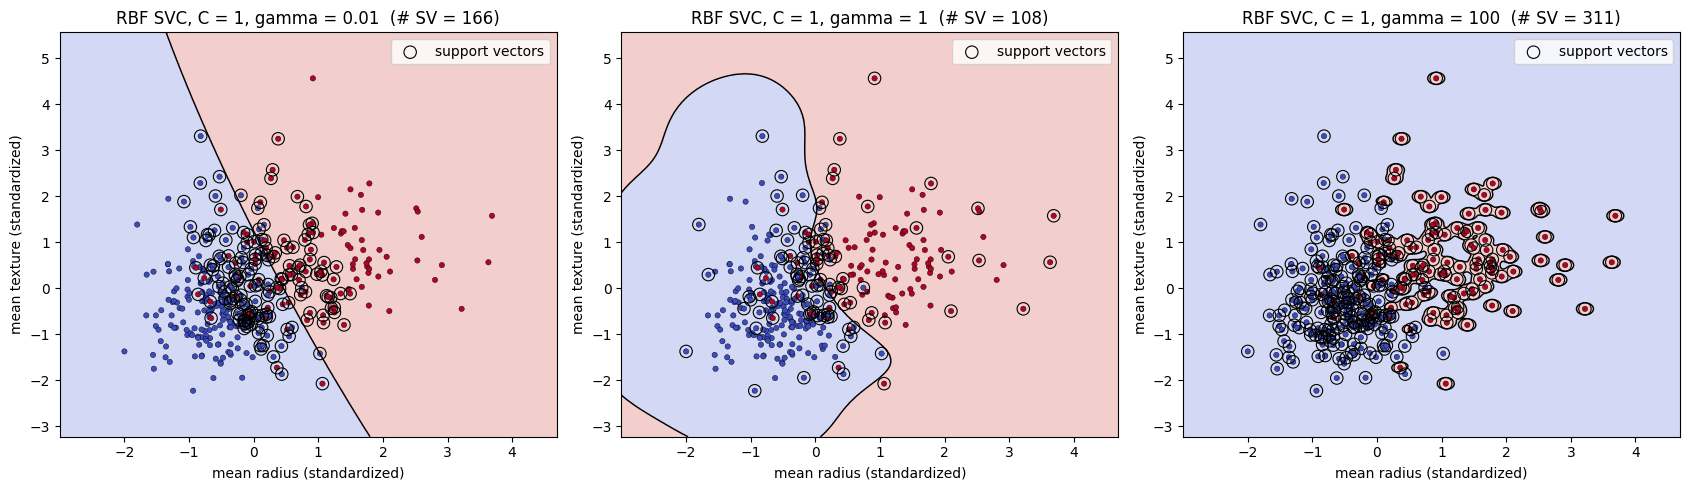

In [32]:
x_min, x_max = X2_tr[:, 0].min() - 1, X2_tr[:, 0].max() + 1
y_min, y_max = X2_tr[:, 1].min() - 1, X2_tr[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, g in zip(ax, [0.01, 1, 100]):
  model = rbf_models[g]
  Z = model.predict(grid).reshape(xx.shape)
  a.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
  a.contour(xx, yy, model.decision_function(grid).reshape(xx.shape), levels=[0], colors="k", linewidths=1)
  a.scatter(X2_tr[:, 0], X2_tr[:, 1], c=yC_tr, cmap="coolwarm", s=15, edgecolors="k", linewidths=0.3)
  sv = model.support_vectors_
  a.scatter(sv[:, 0], sv[:, 1], s=80, facecolors="none", edgecolors="k", linewidths=0.8, label="support vectors")
  a.set_title(f"RBF SVC, C = 1, gamma = {g}  (# SV = {len(sv)})")
  a.set_xlabel("mean radius (standardized)")
  a.set_ylabel("mean texture (standardized)")
  a.legend(loc="upper right")
plt.tight_layout()
plt.show()

Small γ gives a very wide kernel, so the boundary is smooth and almost a straight line, like a linear model. Large γ makes each support vector's influence very local. The boundary then wraps small islands around individual training points: training accuracy shoots up, validation accuracy collapses, and nearly every point becomes a support vector.

## **Task 28: Tuning on Digits (RBF SVC + GridSearchCV)**

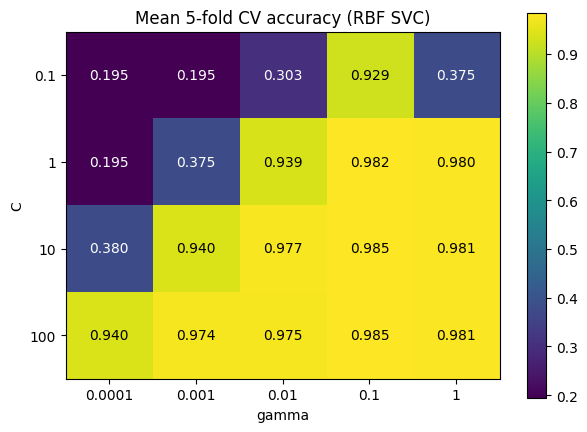

Best params: {'C': 10, 'gamma': 0.1}
Best CV accuracy: 0.9851
Test accuracy: 0.9916666666666667


In [33]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {"C": [0.1, 1, 10, 100], "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1]}
gs = GridSearchCV(SVC(kernel="rbf"), param_grid,
                  cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
gs.fit(XDG_tr, yDG_tr)

scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(scores, cmap="viridis")
ax.set_xticks(range(len(param_grid["gamma"])), [str(g) for g in param_grid["gamma"]])
ax.set_yticks(range(len(param_grid["C"])), [str(c) for c in param_grid["C"]])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
for i in range(scores.shape[0]):
  for j in range(scores.shape[1]):
    ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center",
            color="white" if scores[i, j] < 0.6 else "black")
ax.set_title("Mean 5-fold CV accuracy (RBF SVC)")
fig.colorbar(im)
plt.show()

print("Best params:", gs.best_params_)
print("Best CV accuracy:", round(gs.best_score_, 4))
print("Test accuracy:", accuracy(yDG_te, gs.best_estimator_.predict(XDG_te)))

γ sets how flexible each kernel bump is and C sets how hard the SVM tries to fit the training points, and both push the model the same way, toward more complexity. A small γ (very smooth kernel) needs a large C to bend the boundary enough to fit the data, while a large γ is already flexible enough that only a small C keeps it from overfitting. So roughly the same effective complexity, and the same accuracy, is reached along a diagonal of (large C, small γ) ↔ (small C, larger γ) pairs.